# Практическая работа №8

Логарифмируем ряд:

$$
z_t=\ln(y_t)
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

df = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv')
df['Month'] = pd.to_datetime(df['Month'])
df = df.set_index('Month').asfreq('MS')

series = df['Passengers']
log_series = np.log(series)
split = int(len(series) * 0.8)
train_log = log_series.iloc[:split]
test = series.iloc[split:]

## 1. Проверка стационарности

Применим расширенный тест Дики—Фуллера (ADF). При $p < 0.05$ считаем ряд стационарным.

In [2]:
p_value = adfuller(train_log, autolag='AIC')[1]
print(f'ADF p-value: {p_value:.4f}')
print('Вывод: ряд стационарен.' if p_value < 0.05 else 'Вывод: ряд нестационарен.')

ADF p-value: 0.4966
Вывод: ряд нестационарен.


/tmp/ipykernel_2421/4135302979.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(train_log, autolag='AIC')[1]


## 2. Дифференцирование ряда

Если ряд нестационарен, последовательно вычисляем разности и повторяем ADF-тест:


$$
u_t = y_t - y_{t-1}
$$



$$
u_t^{(2)} = u_t - u_{t-1}
$$

In [3]:
d = 0
diff_series = train_log.copy()

while p_value >= 0.05:
    diff_series = diff_series.diff().dropna()
    d += 1
    p_value = adfuller(diff_series, autolag='AIC')[1]
    print(f'После {d}-го дифференцирования: p-value = {p_value:.4g}')

print(f'Вывод: стационарность достигнута, d = {d}.')

После 1-го дифференцирования: p-value = 0.08581
После 2-го дифференцирования: p-value = 5.923e-11
Вывод: стационарность достигнута, d = 2.


/tmp/ipykernel_2421/1454350839.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(diff_series, autolag='AIC')[1]
/tmp/ipykernel_2421/1454350839.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_value = adfuller(diff_series, autolag='AIC')[1]


## 3. Подбор параметров p и q по ACF и PACF

ACF показывает автокорреляцию ряда с предыдущими значениями (лагами), PACF — частную автокорреляцию. По первым значимым пикам PACF выбираем $p$, по ACF — $q$.

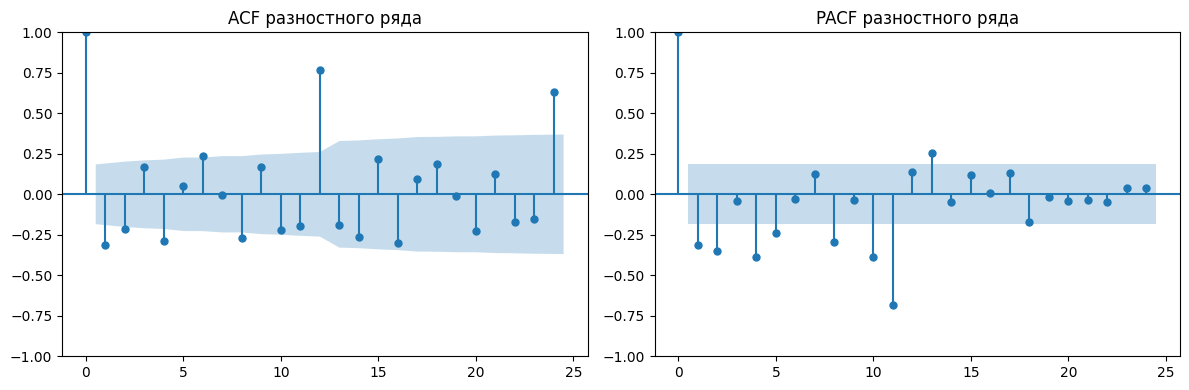

Выбраны параметры: p = 2, d = 2, q = 2.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(diff_series, lags=24, ax=axes[0])
plot_pacf(diff_series, lags=24, method='ywm', ax=axes[1])
axes[0].set_title('ACF разностного ряда')
axes[1].set_title('PACF разностного ряда')
plt.tight_layout()
plt.show()

p, q = 2, 2
print(f'Выбраны параметры: p = {p}, d = {d}, q = {q}.')

На первых двух лагах ACF и PACF есть заметные пики, поэтому в качестве простого варианта берём $p=2$ и $q=2$. Пик на лаге 12 также указывает на сезонность ряда.

## 4. Обучение модели ARIMA

Обучаем ARIMA$(p,d,q)$ на первых 80% логарифмированного ряда.

In [5]:
model = ARIMA(train_log, order=(p, d, q))
result = model.fit(method_kwargs={'maxiter': 100})
print(f'Обучена модель ARIMA({p}, {d}, {q}) на {len(train_log)} наблюдениях.')

Обучена модель ARIMA(2, 2, 2) на 115 наблюдениях.


## 5. Прогноз и оценка MSE

Прогнозируем оставшиеся 20% наблюдений. Чтобы сравнить с фактическими значениями, возвращаемся от логарифмов к исходному масштабу через $e^z$.

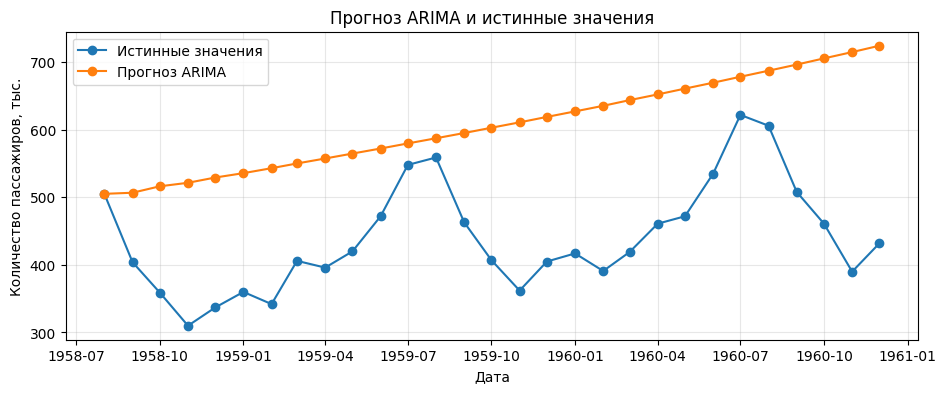

MSE прогноза ARIMA: 33553.15


In [6]:
forecast_log = result.forecast(steps=len(test))
forecast = pd.Series(np.exp(forecast_log.to_numpy()), index=test.index)

plt.figure(figsize=(11, 4))
plt.plot(test.index, test, label='Истинные значения', marker='o')
plt.plot(forecast.index, forecast, label='Прогноз ARIMA', marker='o')
plt.title('Прогноз ARIMA и истинные значения')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров, тыс.')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

mse = mean_squared_error(test, forecast)
print(f'MSE прогноза ARIMA: {mse:.2f}')

## Дополнительное задание. Автоматический подбор параметров

С помощью auto_arima автоматически подберём p, d и q для обычной ARIMA (без сезонных параметров), затем посчитаем MSE на тех же тестовых данных.

In [7]:
%pip -q install pmdarima==2.1.1

In [8]:
from pmdarima import auto_arima

auto_model = auto_arima(train_log, seasonal=False, stepwise=True,
                        start_p=0, start_q=0, max_p=3, max_q=3,
                        suppress_warnings=True, error_action='ignore')

auto_forecast = np.exp(auto_model.predict(n_periods=len(test)))
auto_mse = mean_squared_error(test, auto_forecast)

print('Автоматически подобранный порядок (p, d, q):', auto_model.order)
print(f'MSE auto_arima: {auto_mse:.2f}')
print(f'MSE ARIMA с ручным выбором: {mse:.2f}')

Автоматически подобранный порядок (p, d, q): (0, 1, 2)
MSE auto_arima: 16985.03
MSE ARIMA с ручным выбором: 33553.15


## Дополнительное задание. Сезонная модель SARIMA

SARIMA учитывает не только тренд и зависимости между наблюдениями, но и сезонность.

SARIMA(p,d,q)(P,D,Q,m), где:
- p, d, q — обычные параметры ARIMA;
- P, D, Q — сезонные параметры;
- m = 12 — период сезонности (12 месяцев).

Автоматически подберём параметры SARIMA и сравним точность прогноза с ARIMA.

In [9]:
# Автоматический подбор сезонной модели SARIMA
sarima_model = auto_arima(
    train_log,
    seasonal=True,
    m=12,
    stepwise=True,
    start_p=0, start_q=0,
    max_p=3, max_q=3,
    start_P=0, start_Q=0,
    max_P=1, max_Q=1,
    suppress_warnings=True,
    error_action='ignore'
)

# Прогноз на тестовых данных
sarima_forecast = np.exp(sarima_model.predict(n_periods=len(test)))

# Оценка ошибки
sarima_mse = mean_squared_error(test, sarima_forecast)

print('Параметры SARIMA:', sarima_model.order)
print('Сезонные параметры:', sarima_model.seasonal_order)
print(f'MSE SARIMA: {sarima_mse:.2f}')
print(f'MSE auto_ARIMA: {auto_mse:.2f}')
print(f'MSE ручной ARIMA: {mse:.2f}')

Параметры SARIMA: (2, 0, 0)
Сезонные параметры: (0, 1, 1, 12)
MSE SARIMA: 1330.34
MSE auto_ARIMA: 16985.03
MSE ручной ARIMA: 33553.15


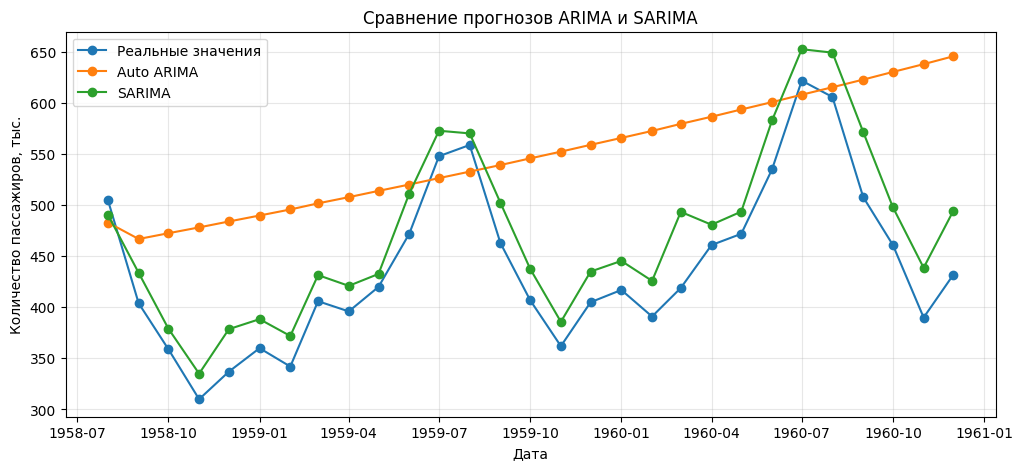

    Модель      MSE
     ARIMA 33553.15
Auto ARIMA 16985.03
    SARIMA  1330.34

Лучшая модель по MSE: SARIMA


In [10]:
plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label='Реальные значения', marker='o')
plt.plot(test.index, auto_forecast, label='Auto ARIMA', marker='o')
plt.plot(test.index, sarima_forecast, label='SARIMA', marker='o')

plt.title('Сравнение прогнозов ARIMA и SARIMA')
plt.xlabel('Дата')
plt.ylabel('Количество пассажиров, тыс.')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Сравнение точности моделей
results = pd.DataFrame({
    'Модель': ['ARIMA', 'Auto ARIMA', 'SARIMA'],
    'MSE': [mse, auto_mse, sarima_mse]
})

print(results.round(2).to_string(index=False))
print('\nЛучшая модель по MSE:', results.loc[results['MSE'].idxmin(), 'Модель'])